In [1]:
import pandas as pd

df = pd.read_csv('wine_quality_merged.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


In [2]:
df.shape
df['quality'].value_counts().sort_index()

3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: quality, dtype: int64

In [3]:
df.shape
df.info()
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   object 
dtypes: float64(11), int64(1), object(1)
memory usage: 660.0+ KB


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64

In [4]:
df['quality'].value_counts().sort_index()

3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: quality, dtype: int64

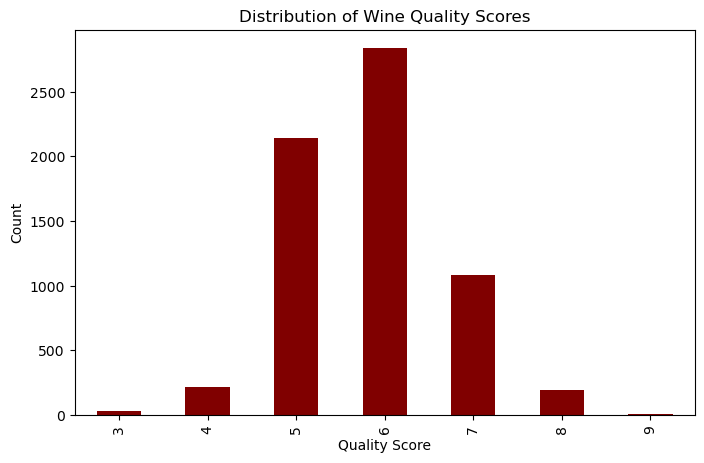

In [5]:
import matplotlib.pyplot as plt

df['quality'].value_counts().sort_index().plot(kind='bar', color='maroon', figsize=(8,5))
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

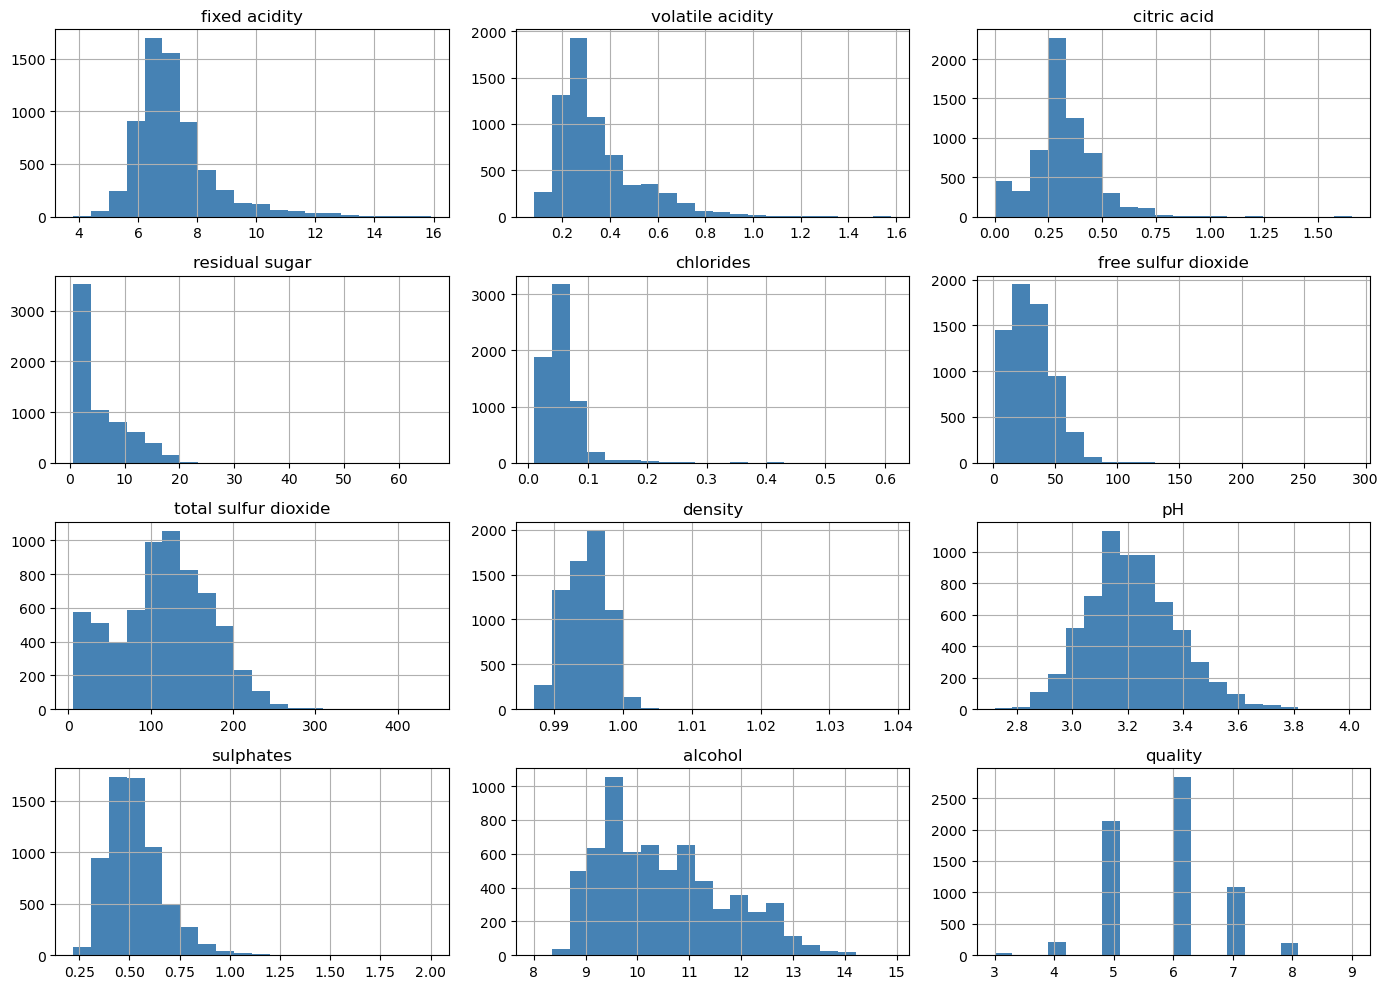

In [6]:
df.hist(figsize=(14,10), bins=20, color='steelblue')
plt.tight_layout()
plt.show()

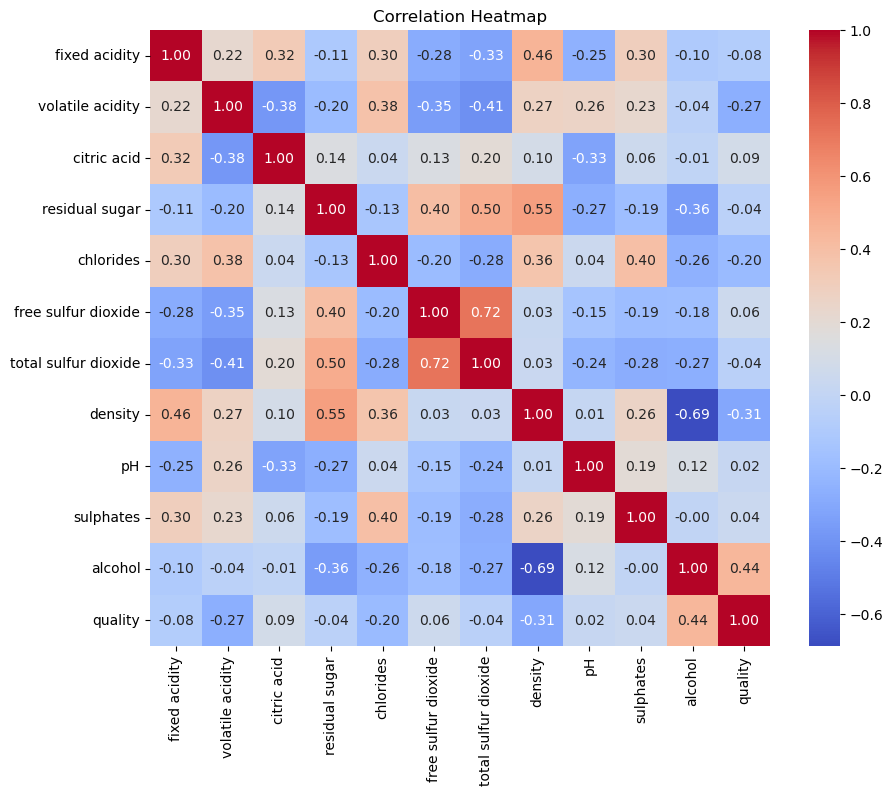

In [7]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(df.drop('type', axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## Class Imbalance Discussion

Note here which quality scores are rare (e.g. 3, 4, 8) vs common (5, 6, 7), 
and explain that models trained on imbalanced data tend to get very good at 
predicting the common classes but perform poorly on rare ones, since there's 
little data to learn those patterns from.

In [9]:
def quality_to_label(q):
    if q <= 5:
        return 'Low'
    elif q <= 6:
        return 'Medium'
    else:
        return 'High'

df['quality_label'] = df['quality'].apply(quality_to_label)
df['quality_label'].value_counts()

Medium    2836
Low       2384
High      1277
Name: quality_label, dtype: int64

In [10]:
## Why I Binned Quality Into 3 Classes

The raw quality scores range from 3-8, but scores like 3, 4, and 8 are rare, 
making a 6-class model hard to train well. Grouping into Low (<=5), Medium (6), 
and High (>=7) creates more balanced, meaningful categories that better reflect 
real-world wine quality tiers, while still preserving more nuance than a simple 
binary good/bad split.

SyntaxError: invalid syntax (4125897911.py, line 3)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['quality_encoded'] = le.fit_transform(df['quality_label'])

X = df.drop(['quality', 'quality_label', 'quality_encoded', 'type'], axis=1)
y = df['quality_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)

(5197, 11) (1300, 11)


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

# Scale features (SGD and SVC need this, Random Forest doesn't but it won't hurt)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

sgd = SGDClassifier(random_state=42)
sgd.fit(X_train_scaled, y_train)
sgd_pred = sgd.predict(X_test_scaled)

svc = SVC(random_state=42)
svc.fit(X_train_scaled, y_train)
svc_pred = svc.predict(X_test_scaled)

In [13]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

for name, pred in [('Random Forest', rf_pred), ('SGD', sgd_pred), ('SVC', svc_pred)]:
    print(f"--- {name} ---")
    print("Accuracy:", accuracy_score(y_test, pred))
    print(classification_report(y_test, pred, target_names=le.classes_))
    print()

--- Random Forest ---
Accuracy: 0.7284615384615385
              precision    recall  f1-score   support

        High       0.77      0.61      0.68       256
         Low       0.78      0.75      0.77       477
      Medium       0.67      0.76      0.71       567

    accuracy                           0.73      1300
   macro avg       0.74      0.71      0.72      1300
weighted avg       0.73      0.73      0.73      1300


--- SGD ---
Accuracy: 0.5507692307692308
              precision    recall  f1-score   support

        High       0.37      0.04      0.08       256
         Low       0.67      0.60      0.63       477
      Medium       0.50      0.74      0.60       567

    accuracy                           0.55      1300
   macro avg       0.51      0.46      0.43      1300
weighted avg       0.53      0.55      0.51      1300


--- SVC ---
Accuracy: 0.6292307692307693
              precision    recall  f1-score   support

        High       0.63      0.34      0.44     

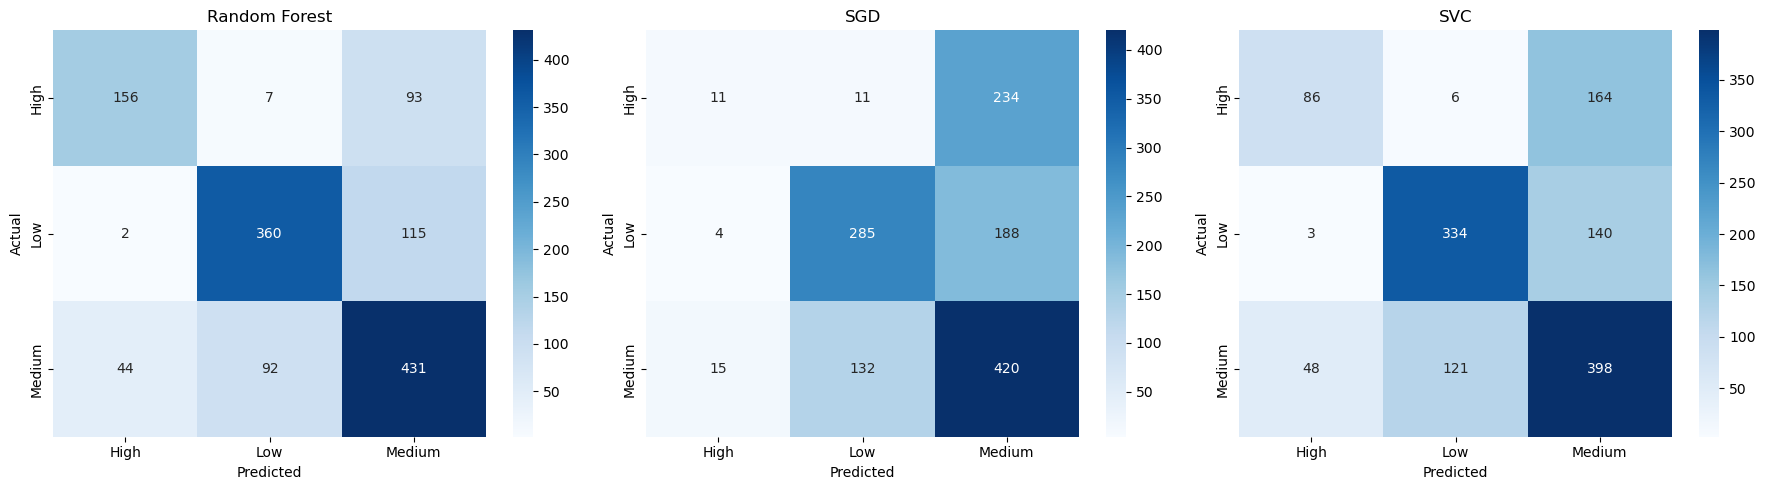

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, (name, pred) in zip(axes, [('Random Forest', rf_pred), ('SGD', sgd_pred), ('SVC', svc_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=le.classes_, yticklabels=le.classes_)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

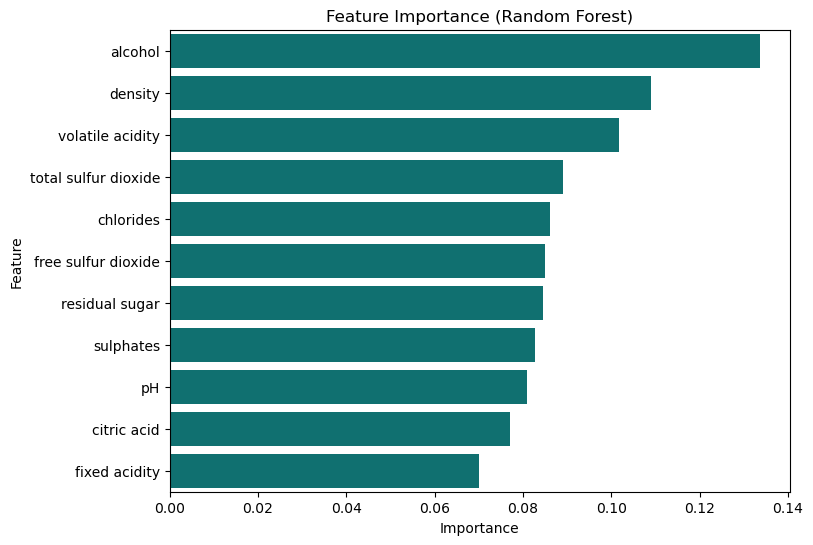

In [15]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(data=importance, x='Importance', y='Feature', color='teal')
plt.title('Feature Importance (Random Forest)')
plt.show()

In [16]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'SGD', 'SVC'],
    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, sgd_pred),
        accuracy_score(y_test, svc_pred)
    ]
})
comparison

,Model,Accuracy
0,Random Forest,0.728462
1,SGD,0.550769
2,SVC,0.629231
